In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

train_df = pd.read_csv("dataset_train_scaled.csv")
test_df = pd.read_csv("dataset_test_scaled.csv")

print("Ukuran data training:", train_df.shape)
print("Ukuran data testing:", test_df.shape)

display(train_df.head())

Ukuran data training: (1600, 8)
Ukuran data testing: (400, 8)


,mq2_value,temperature_c,humidity_percent,fire_confidence,smoke_confidence,fire_detected,smoke_detected,label
0,-0.631961,0.258521,0.813242,-0.744145,-0.689870,-0.583124,-0.795395,Normal
1,-0.654843,-1.089399,0.543458,-0.680574,-0.646809,-0.583124,-0.795395,Normal
2,-0.718913,-0.722883,0.349042,-0.662916,-0.673308,-0.583124,-0.795395,Normal
3,-0.924850,-0.537611,0.401286,-0.694701,-0.636872,-0.583124,-0.795395,Normal
4,-0.581621,-0.764502,-0.462880,-0.560496,-0.732931,-0.583124,-0.795395,Normal


In [2]:
X_train = train_df.drop(columns=["label"])
y_train = train_df["label"]

X_test = test_df.drop(columns=["label"])
y_test = test_df["label"]

X_test = X_test[X_train.columns]

print("Jumlah fitur:", X_train.shape[1])
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label testing:")
print(y_test.value_counts())

Jumlah fitur: 7
Jumlah data training: 1600
Jumlah data testing: 400

Distribusi label training:
label
Normal        800
Peringatan    480
Kebakaran     320
Name: count, dtype: int64

Distribusi label testing:
label
Normal        200
Peringatan    120
Kebakaran      80
Name: count, dtype: int64


In [3]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Training Random Forest selesai.")
print("Jumlah pohon:", rf_model.n_estimators)
print("Kelas model:", rf_model.classes_)

Training Random Forest selesai.
Jumlah pohon: 200
Kelas model: ['Kebakaran' 'Normal' 'Peringatan']


In [4]:
y_pred = rf_model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "Label Aktual": y_test,
    "Hasil Prediksi": y_pred
})

display(hasil_prediksi.head(15))

,Label Aktual,Hasil Prediksi
0,Normal,Normal
1,Normal,Normal
2,Peringatan,Peringatan
3,Normal,Normal
4,Normal,Normal
5,Normal,Normal
6,Normal,Normal
7,Peringatan,Peringatan
8,Normal,Normal
9,Kebakaran,Kebakaran


In [5]:
y_proba = rf_model.predict_proba(X_test)

hasil_probabilitas = pd.DataFrame(
    y_proba,
    columns=rf_model.classes_,
    index=X_test.index
)

display(hasil_probabilitas.head(10))

,Kebakaran,Normal,Peringatan
0,0.000,1.00,0.000
1,0.000,1.00,0.000
2,0.000,0.00,1.000
3,0.000,1.00,0.000
4,0.000,1.00,0.000
5,0.005,0.99,0.005
6,0.000,1.00,0.000
7,0.055,0.00,0.945
8,0.000,1.00,0.000
9,1.000,0.00,0.000


In [6]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 99.50%


In [7]:
report = classification_report(
    y_test,
    y_pred,
    labels=["Normal", "Peringatan", "Kebakaran"],
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       200
  Peringatan       0.99      0.99      0.99       120
   Kebakaran       0.99      1.00      0.99        80

    accuracy                           0.99       400
   macro avg       0.99      1.00      0.99       400
weighted avg       1.00      0.99      1.00       400



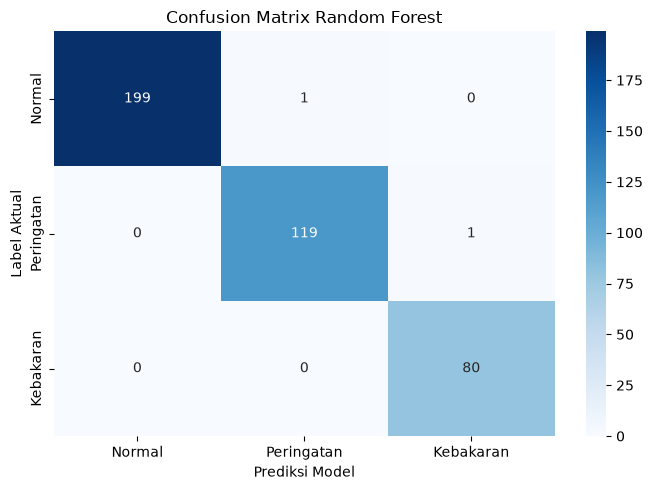

In [8]:
labels = ["Normal", "Peringatan", "Kebakaran"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix Random Forest")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

,Fitur,Importance
0,mq2_value,0.360262
1,temperature_c,0.221875
3,fire_confidence,0.161297
4,smoke_confidence,0.158381
6,smoke_detected,0.038129
5,fire_detected,0.037046
2,humidity_percent,0.023012


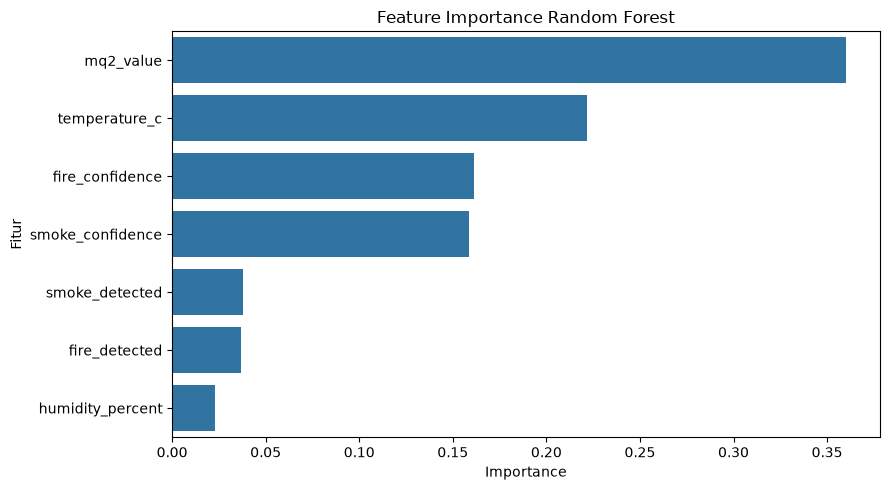

In [9]:
importance = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Fitur"
)

plt.title("Feature Importance Random Forest")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [10]:

from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_kebakaran = recall_score(
    y_test, y_pred,
    labels=["Kebakaran"],
    average="macro",
    zero_division=0
)

evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1-Score Macro",
        "Recall Kebakaran"
    ],
    "Nilai (%)": [
        accuracy * 100,
        precision_macro * 100,
        recall_macro * 100,
        f1_macro * 100,
        recall_kebakaran * 100
    ]
})

display(evaluasi.round(2))


,Metrik,Nilai (%)
0,Accuracy,99.50
1,Precision Macro,99.31
2,Recall Macro,99.56
3,F1-Score Macro,99.43
4,Recall Kebakaran,100.00


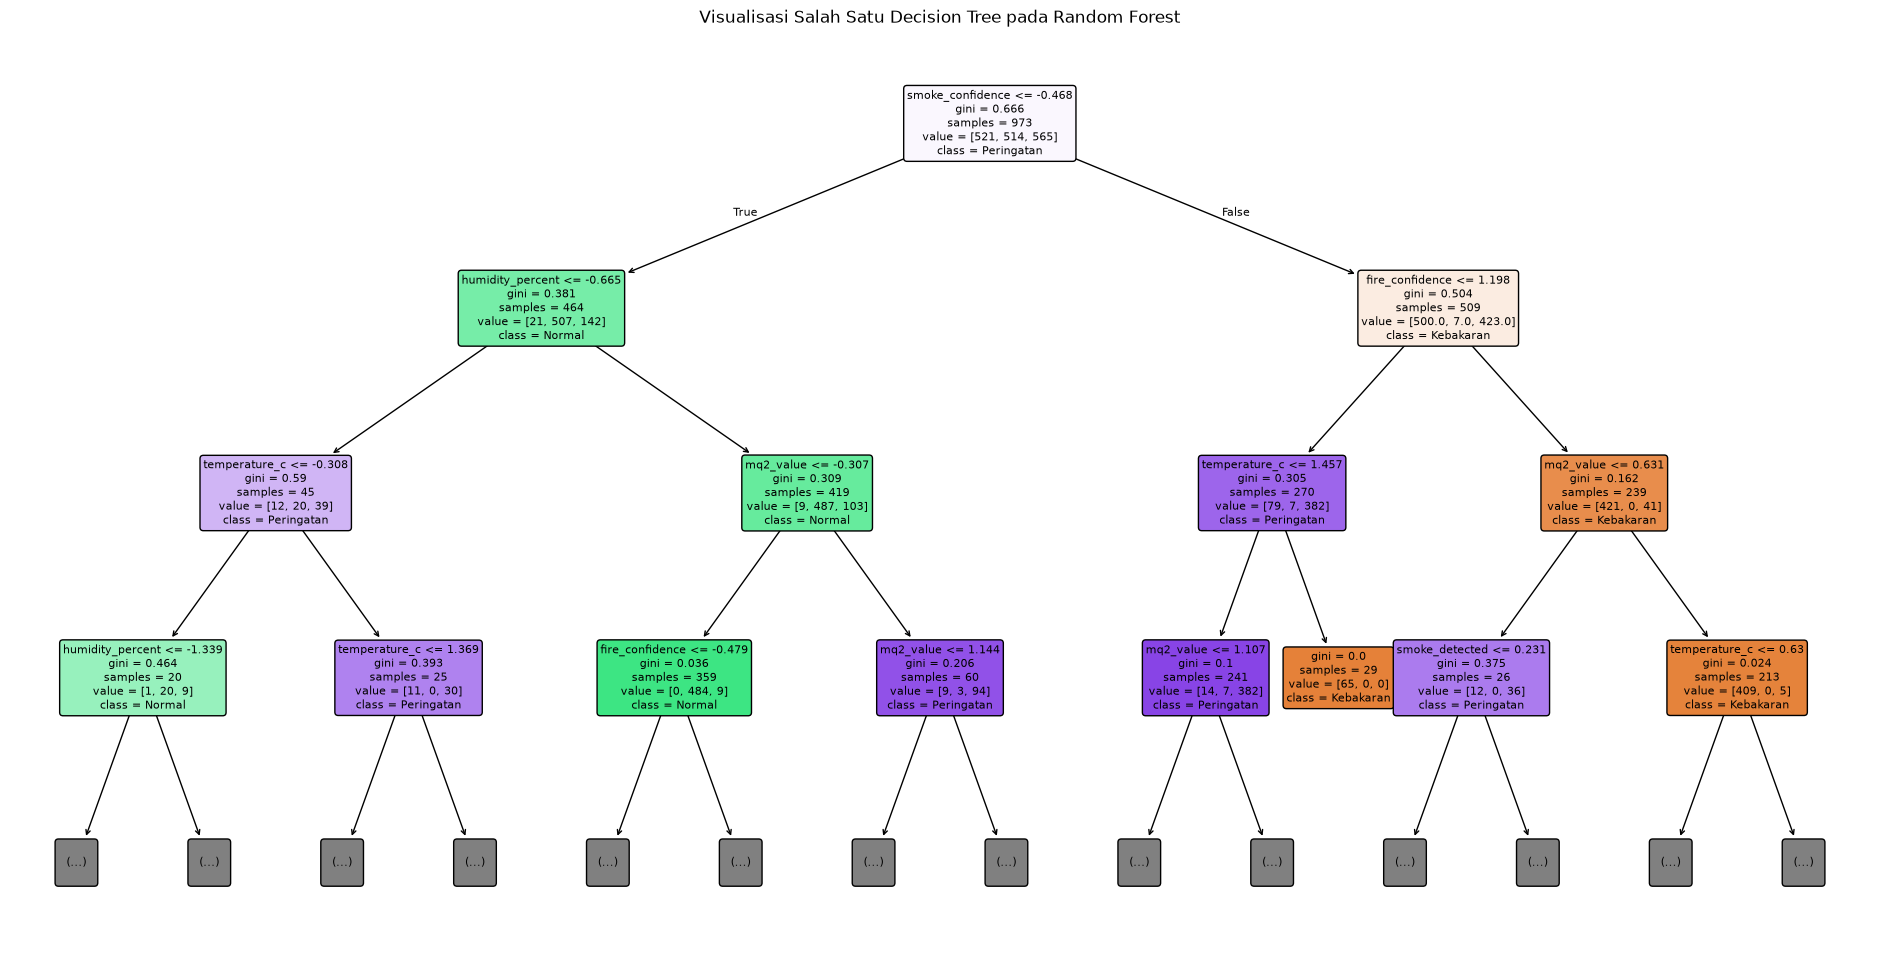

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    rf_model.estimators_[0],
    feature_names=X_train.columns,
    class_names=rf_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Visualisasi Salah Satu Decision Tree pada Random Forest")
plt.show()

In [12]:
from sklearn.tree import export_text

tree_rules = export_text(
    rf_model.estimators_[0],
    feature_names=list(X_train.columns),
    max_depth=4
)

print(tree_rules)

|--- smoke_confidence <= -0.47
|   |--- humidity_percent <= -0.67
|   |   |--- temperature_c <= -0.31
|   |   |   |--- humidity_percent <= -1.34
|   |   |   |   |--- class: 1.0
|   |   |   |--- humidity_percent >  -1.34
|   |   |   |   |--- smoke_confidence <= -0.83
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- smoke_confidence >  -0.83
|   |   |   |   |   |--- truncated branch of depth 2
|   |   |--- temperature_c >  -0.31
|   |   |   |--- temperature_c <= 1.37
|   |   |   |   |--- mq2_value <= 1.44
|   |   |   |   |   |--- class: 2.0
|   |   |   |   |--- mq2_value >  1.44
|   |   |   |   |   |--- class: 0.0
|   |   |   |--- temperature_c >  1.37
|   |   |   |   |--- class: 0.0
|   |--- humidity_percent >  -0.67
|   |   |--- mq2_value <= -0.31
|   |   |   |--- fire_confidence <= -0.48
|   |   |   |   |--- class: 1.0
|   |   |   |--- fire_confidence >  -0.48
|   |   |   |   |--- class: 2.0
|   |   |--- mq2_value >  -0.31
|   |   |   |--- mq2_value <= 1.14
| 

In [13]:
import joblib

joblib.dump(rf_model, "random_forest_deteksi_kebakaran.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!
